# White Blood Cell Classification — Approche classique

**IMA205 — Machine Learning Challenge**

Ce notebook implémente une **première approche** pour le challenge de classification de globules blancs (WBC).  
L'idée est d'extraire des **caractéristiques morphologiques, de couleur et de texture** directement à partir des images,  
puis d'entraîner des **classifieurs supervisés classiques** (Logistic Regression, SVM, Random Forest, MLP).

Cette approche, dite *handcrafted features + ML classique*, est cohérente avec les TP du cours :  
on construit manuellement un vecteur de features pour chaque image, on normalise, on entraîne, on évalue avec le **macro-F1 score**.

Le dataset contient **13 classes** très déséquilibrées : de SNE (environ 13 000 images) à PLY (11 images).

## 1. Load packages

In [1]:
# Load packages
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from skimage.color import rgb2hsv, rgb2lab, rgb2gray
from skimage.filters import threshold_otsu
from skimage.measure import regionprops, label as sk_label
from skimage.morphology import binary_opening, binary_closing, disk, remove_small_objects
from skimage.feature import graycomatrix, graycoprops
from skimage.transform import resize

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
%matplotlib inline

np.random.seed(42)

In [2]:
# Versions
import sys, sklearn, skimage
print(f"Python  : {sys.version}")
print(f"NumPy   : {np.__version__}")
print(f"Pandas  : {pd.__version__}")
print(f"Sklearn : {sklearn.__version__}")
print(f"Skimage : {skimage.__version__}")

Python  : 3.12.12 (main, Mar 27 2026, 00:00:00) [GCC 14.3.1 20250617 (Red Hat 14.3.1-2)]
NumPy   : 2.4.4
Pandas  : 3.0.2
Sklearn : 1.8.0
Skimage : 0.26.0


## 2. Configuration

On définit ici les chemins vers les données et les paramètres globaux.  
Modifiez ces variables si votre arborescence est différente.

In [3]:
# ----- Paths -----
DATA_DIR       = os.path.dirname(os.path.abspath("__file__"))  # dossier du notebook
# Si le cwd n'est pas celui du notebook, forcer le chemin :
if not os.path.exists(os.path.join(DATA_DIR, "train_metadata.csv")):
    DATA_DIR = os.path.expanduser("~/kaggle-im05")
TRAIN_DIR      = os.path.join(DATA_DIR, "train")
TEST_DIR       = os.path.join(DATA_DIR, "test")
TRAIN_CSV      = os.path.join(DATA_DIR, "train_metadata.csv")
TEST_CSV       = os.path.join(DATA_DIR, "test_metadata.csv")
SAMPLE_SUB_CSV = os.path.join(DATA_DIR, "sample_submission.csv")
OUTPUT_DIR     = os.path.join(DATA_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ----- Column names -----
COL_ID    = "ID"
COL_LABEL = "label"

# ----- Misc -----
SEED       = 42
IMG_SIZE   = 128          # taille de redimensionnement pour l'extraction de features
VAL_RATIO  = 0.2          # proportion du split validation

## 3. Utility functions

On définit quelques fonctions utilitaires pour la visualisation et le chargement des données.

In [4]:
def load_image(path, size=IMG_SIZE):
    """Charge une image RGB et la redimensionne. Retourne None si l'image est corrompue."""
    try:
        img = np.array(Image.open(path).convert("RGB"))
    except Exception:
        return None
    img = resize(img, (size, size, 3), anti_aliasing=True)
    img = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)
    return img


def show_images(images, titles=None, ncols=5, figsize=(15, 3)):
    """Affiche une grille d'images."""
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0], figsize[1]*nrows))
    axes = np.atleast_2d(axes)
    for i, ax in enumerate(axes.flat):
        if i < n:
            ax.imshow(images[i])
            if titles is not None:
                ax.set_title(titles[i], fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, classes, title="Confusion Matrix"):
    """Affiche une matrice de confusion avec seaborn."""
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()



def macro_f1(y_true, y_pred):    return f1_score(y_true, y_pred, average="macro")
    #Calcule le macro-F1 score

## 4. Read data

On charge le CSV d'entraînement, on construit les chemins vers les images  
et on affiche quelques statistiques sur le dataset.

In [5]:
# Read data
df_train = pd.read_csv(TRAIN_CSV)
df_test  = pd.read_csv(TEST_CSV)

# Construire les chemins complets
df_train["path"] = df_train[COL_ID].apply(lambda x: os.path.join(TRAIN_DIR, x))
df_test["path"]  = df_test[COL_ID].apply(lambda x: os.path.join(TEST_DIR, x))

# Filtrer les fichiers vides ou corrompus
df_train["filesize"] = df_train["path"].apply(lambda p: os.path.getsize(p) if os.path.exists(p) else 0)
df_test["filesize"]  = df_test["path"].apply(lambda p: os.path.getsize(p) if os.path.exists(p) else 0)
n_before = len(df_train)
df_train = df_train[df_train["filesize"] > 0].reset_index(drop=True)
df_test  = df_test[df_test["filesize"] > 0].reset_index(drop=True)

print(f"Images train valides : {len(df_train)} / {n_before} (fichiers vides retirés : {n_before - len(df_train)})")
print(df_train[COL_LABEL].value_counts())

print()

print(f"Nombre d'images train : {len(df_train)}")
print(f"Classes               : {sorted(df_train[COL_LABEL].unique())}")

print(f"Nombre d'images test  : {len(df_test)}")
print(f"Nombre de classes     : {df_train[COL_LABEL].nunique()}")

Images train valides : 28901 / 28901 (fichiers vides retirés : 0)
label
SNE    13015
LY      8101
MO      2746
BL      2012
EO       861
MY       441
BA       415
BNE      391
VLY      366
MMY      360
PMY      114
PC        68
PLY       11
Name: count, dtype: int64

Nombre d'images train : 28901
Classes               : ['BA', 'BL', 'BNE', 'EO', 'LY', 'MMY', 'MO', 'MY', 'PC', 'PLY', 'PMY', 'SNE', 'VLY']
Nombre d'images test  : 9634
Nombre de classes     : 13


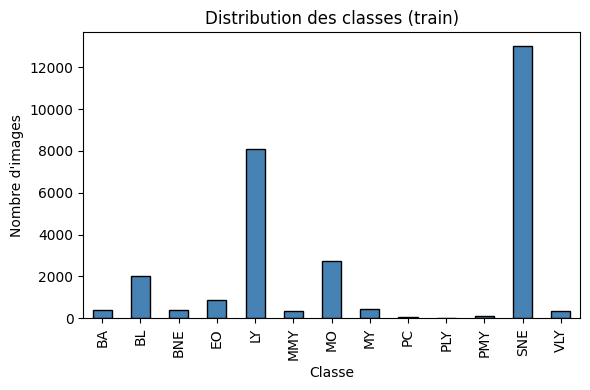

In [6]:
# Barplot de la distribution des classes
fig, ax = plt.subplots(figsize=(6, 4))
df_train[COL_LABEL].value_counts().sort_index().plot.bar(ax=ax, color="steelblue", edgecolor="k")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'images")
ax.set_title("Distribution des classes (train)")
plt.tight_layout()
plt.show()

## 5. Plot a few examples

Visualisons quelques images de chaque classe pour se familiariser avec les données.



In [7]:
# Plot a few examples
n_per_class = 3
classes = sorted(df_train[COL_LABEL].unique())

sample_imgs, sample_titles = [], []
for cls in classes:
    subset = df_train[df_train[COL_LABEL] == cls].sample(n_per_class, random_state=SEED)
    for _, row in subset.iterrows():
        img = load_image(row["path"])
        if img is None:
            continue
        sample_imgs.append(img)
        sample_titles.append(cls)


show_images(sample_imgs, sample_titles, ncols=n_per_class*len(classes),            figsize=(3*n_per_class*len(classes), 3))

## 6. Create training and validation sets

On sépare le jeu d'entraînement en **train** et **validation** avec un split stratifié.  
Le jeu de test Kaggle n'est pas utilisé dans ce notebook.

In [8]:
# Create training and validation sets
train_df, val_df = train_test_split(
    df_train, test_size=VAL_RATIO, stratify=df_train[COL_LABEL], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f"Train : {len(train_df)} images")
print(f"Val   : {len(val_df)} images")
print()
print("Proportions train :")
print(train_df[COL_LABEL].value_counts(normalize=True).sort_index().round(3))
print()
print("Proportions val :")
print(val_df[COL_LABEL].value_counts(normalize=True).sort_index().round(3))

Train : 23120 images
Val   : 5781 images

Proportions train :
label
BA     0.014
BL     0.070
BNE    0.014
EO     0.030
LY     0.280
MMY    0.012
MO     0.095
MY     0.015
PC     0.002
PLY    0.000
PMY    0.004
SNE    0.450
VLY    0.013
Name: proportion, dtype: float64

Proportions val :
label
BA     0.014
BL     0.070
BNE    0.013
EO     0.030
LY     0.280
MMY    0.012
MO     0.095
MY     0.015
PC     0.002
PLY    0.000
PMY    0.004
SNE    0.450
VLY    0.013
Name: proportion, dtype: float64


## 7. Pre-processing and segmentation

On cherche à extraire un **masque approximatif** de la cellule pour concentrer l'extraction de features  
sur la zone utile. L'approche est simple :
1. Conversion en espace HSV
2. Seuillage sur le canal Saturation (la cellule est généralement plus saturée que le fond)
3. Nettoyage morphologique
4. Sélection du plus grand objet connecté

Si la segmentation échoue (masque vide), on prend l'image entière comme fallback.

In [9]:
def segment_cell(img):
    """
    Segmente approximativement la cellule dans l'image.
    Retourne un masque binaire (bool) de même taille que l'image.
    """
    hsv = rgb2hsv(img)
    sat = hsv[:, :, 1]

    # Seuillage Otsu sur la saturation
    try:
        thresh = threshold_otsu(sat)
        mask = sat > thresh
    except Exception:
        mask = np.ones(img.shape[:2], dtype=bool)
        return mask

    # Nettoyage morphologique
    mask = binary_closing(mask, disk(3))
    mask = binary_opening(mask, disk(3))
    mask = remove_small_objects(mask, min_size=200)

    # Garder le plus grand objet connecté
    labeled = sk_label(mask)
    if labeled.max() == 0:
        return np.ones(img.shape[:2], dtype=bool)  # fallback

    regions = regionprops(labeled)
    largest = max(regions, key=lambda r: r.area)
    mask = labeled == largest.label

    return mask

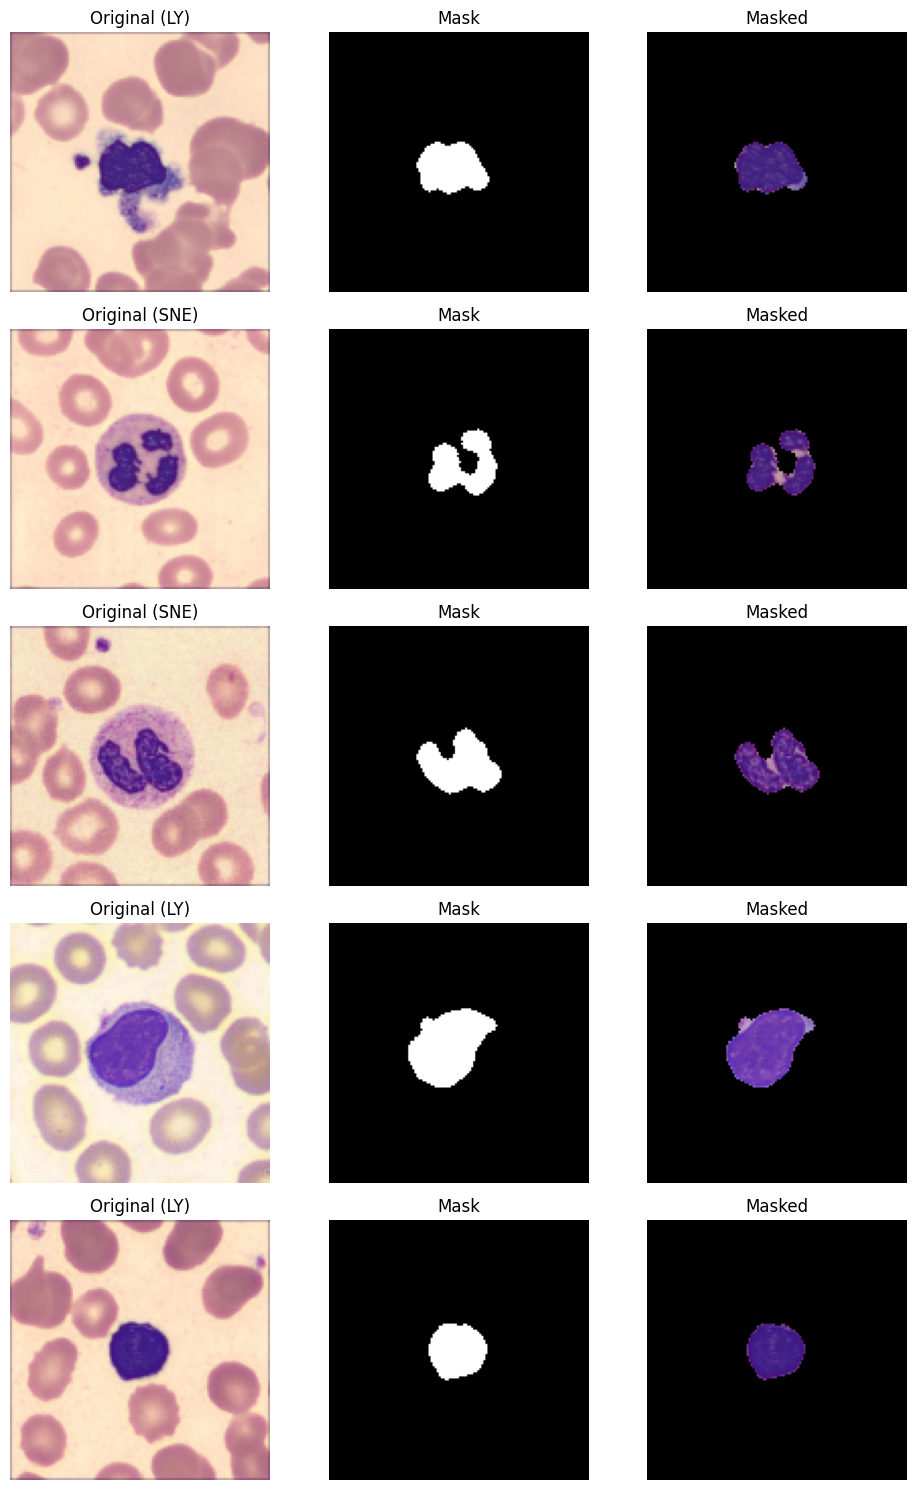

In [10]:
# Visualisation de la segmentation sur quelques exemples
n_show = 5
sample = df_train.sample(n_show, random_state=SEED)

fig, axes = plt.subplots(n_show, 3, figsize=(10, 3*n_show))
for i, (_, row) in enumerate(sample.iterrows()):
    img = load_image(row["path"])
    mask = segment_cell(img)
    masked = img.copy()
    masked[~mask] = 0

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Original ({row[COL_LABEL]})")
    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Mask")
    axes[i, 2].imshow(masked)
    axes[i, 2].set_title("Masked")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Handcrafted feature extraction

On construit une fonction `extract_features(img)` qui prend une image RGB en entrée  
et renvoie un dictionnaire de features numériques. Les features sont organisées en 4 catégories :

- **A. Shape / Morphology** : area, perimeter, eccentricity, solidity, circularity, etc.
- **B. Color** : moyennes et écarts-types sur RGB et HSV (sur la zone segmentée)
- **C. Texture** : GLCM (contrast, homogeneity, energy, correlation), entropy
- **D. Size** : bbox area, filled area, ratios

In [11]:
def extract_features(img):
    """
    Extrait un dictionnaire de features numériques à partir d'une image RGB.
    """
    feats = {}
    h, w = img.shape[:2]
    total_pixels = h * w

    # --- Segmentation ---
    mask = segment_cell(img)
    gray = rgb2gray(img)
    hsv  = rgb2hsv(img)

    # --- A. Shape / Morphology ---
    labeled_mask = sk_label(mask.astype(np.uint8))
    regions = regionprops(labeled_mask)

    if len(regions) > 0:
        props = max(regions, key=lambda r: r.area)
        feats["area"]         = props.area
        feats["perimeter"]    = props.perimeter
        feats["equiv_diam"]   = props.equivalent_diameter
        feats["eccentricity"] = props.eccentricity
        feats["solidity"]     = props.solidity
        feats["extent"]       = props.extent
        feats["filled_area"]  = props.filled_area

        # Circularity
        perim = props.perimeter
        feats["circularity"] = (4 * np.pi * props.area / (perim**2)) if perim > 0 else 0

        # Aspect ratio via bounding box
        minr, minc, maxr, maxc = props.bbox
        bbox_h = maxr - minr
        bbox_w = maxc - minc
        feats["aspect_ratio"] = bbox_h / bbox_w if bbox_w > 0 else 1.0
        feats["bbox_area"]    = bbox_h * bbox_w

        # Area ratios
        feats["area_ratio"]        = props.area / total_pixels
        feats["filled_area_ratio"] = props.filled_area / total_pixels

        # Asymmetry : comparaison haut/bas et gauche/droite du masque
        cy, cx = props.centroid
        cy, cx = int(cy), int(cx)
        top    = mask[:cy, :].sum()
        bottom = mask[cy:, :].sum()
        left   = mask[:, :cx].sum()
        right  = mask[:, cx:].sum()
        total  = mask.sum()
        feats["asymmetry_tb"] = abs(top - bottom) / total if total > 0 else 0
        feats["asymmetry_lr"] = abs(left - right) / total if total > 0 else 0

        # Border irregularity
        feats["border_irreg"] = perim / (2 * np.sqrt(np.pi * props.area)) if props.area > 0 else 0

    else:
        # Fallback si pas de région détectée
        for k in ["area", "perimeter", "equiv_diam", "eccentricity", "solidity",
                  "extent", "filled_area", "circularity", "aspect_ratio", "bbox_area",
                  "area_ratio", "filled_area_ratio", "asymmetry_tb", "asymmetry_lr",
                  "border_irreg"]:
            feats[k] = 0.0

    # --- B. Color features (sur la zone segmentée) ---
    mask_pixels = mask.sum()
    for c, name in enumerate(["R", "G", "B"]):
        channel = img[:, :, c].astype(np.float64)
        if mask_pixels > 0:
            feats[f"mean_{name}"] = channel[mask].mean()
            feats[f"std_{name}"]  = channel[mask].std()
        else:
            feats[f"mean_{name}"] = channel.mean()
            feats[f"std_{name}"]  = channel.std()

    for c, name in enumerate(["H", "S", "V"]):
        channel = hsv[:, :, c]
        if mask_pixels > 0:
            feats[f"mean_{name}"] = channel[mask].mean()
            feats[f"std_{name}"]  = channel[mask].std()
        else:
            feats[f"mean_{name}"] = channel.mean()
            feats[f"std_{name}"]  = channel.std()

    # --- C. Texture features ---
    gray_uint8 = (gray * 255).astype(np.uint8)

    # GLCM
    glcm = graycomatrix(gray_uint8, distances=[1], angles=[0], levels=256,
                        symmetric=True, normed=True)
    feats["glcm_contrast"]    = graycoprops(glcm, "contrast")[0, 0]
    feats["glcm_homogeneity"] = graycoprops(glcm, "homogeneity")[0, 0]
    feats["glcm_energy"]      = graycoprops(glcm, "energy")[0, 0]
    feats["glcm_correlation"] = graycoprops(glcm, "correlation")[0, 0]

    # Entropy
    hist, _ = np.histogram(gray_uint8[mask] if mask_pixels > 0 else gray_uint8,
                           bins=256, range=(0, 256), density=True)
    hist = hist[hist > 0]
    feats["entropy"] = -np.sum(hist * np.log2(hist))

    # Variance d'intensité
    feats["intensity_var"] = gray[mask].var() if mask_pixels > 0 else gray.var()

    # --- D. Size-related ---
    feats["img_height"] = h
    feats["img_width"]  = w

    return feats

In [12]:
# Test rapide sur une image
test_img = load_image(df_train.iloc[0]["path"])
test_feats = extract_features(test_img)
print(f"Nombre de features : {len(test_feats)}")
for k, v in test_feats.items():
    print(f"  {k:25s} : {v:.4f}")

Nombre de features : 35
  area                      : 807.0000
  perimeter                 : 164.8528
  equiv_diam                : 32.0547
  eccentricity              : 0.6257
  solidity                  : 0.7507
  extent                    : 0.5445
  filled_area               : 807.0000
  circularity               : 0.3732
  aspect_ratio              : 0.9744
  bbox_area                 : 1482.0000
  area_ratio                : 0.0493
  filled_area_ratio         : 0.0493
  asymmetry_tb              : 0.0409
  asymmetry_lr              : 0.1747
  border_irreg              : 1.6370
  mean_R                    : 102.0657
  std_R                     : 19.3229
  mean_G                    : 50.8996
  std_G                     : 18.6232
  mean_B                    : 166.0756
  std_B                     : 4.9336
  mean_H                    : 0.7425
  std_H                     : 0.0171
  mean_S                    : 0.6959
  std_S                     : 0.0995
  mean_V                    : 0.65

## 9. Build the feature table

On extrait les features pour **toutes** les images du train et de la validation.  
Cela peut prendre quelques minutes selon la taille du dataset.

In [13]:
def extract_features_from_df(df, desc="Extracting"):
    """Extrait les features pour toutes les images d'un DataFrame."""
    all_feats = []
    t0 = time.time()
    n = len(df)
    for i, (_, row) in enumerate(df.iterrows()):
        img = load_image(row["path"])
        if img is None:
            all_feats.append({})
            continue
        feats = extract_features(img)
        all_feats.append(feats)
        if (i + 1) % 500 == 0 or (i + 1) == n:
            elapsed = time.time() - t0
            print(f"  {desc}: {i+1}/{n}  ({elapsed:.1f}s)")
    return pd.DataFrame(all_feats)

In [14]:
# Extract features — train
print("=== Extraction train ===")
X_train_df = extract_features_from_df(train_df, desc="Train")
y_train = train_df[COL_LABEL].values

print()
print("=== Extraction validation ===")
X_val_df = extract_features_from_df(val_df, desc="Val")
y_val = val_df[COL_LABEL].values

=== Extraction train ===


  Train: 500/23120  (21.3s)
  Train: 1000/23120  (42.8s)
  Train: 1500/23120  (64.0s)
  Train: 2000/23120  (85.6s)
  Train: 2500/23120  (106.2s)
  Train: 3000/23120  (126.8s)
  Train: 3500/23120  (147.7s)
  Train: 4000/23120  (168.4s)
  Train: 4500/23120  (189.2s)
  Train: 5000/23120  (210.2s)
  Train: 5500/23120  (230.8s)
  Train: 6000/23120  (252.0s)
  Train: 6500/23120  (272.6s)
  Train: 7000/23120  (293.3s)
  Train: 7500/23120  (314.5s)
  Train: 8000/23120  (335.5s)
  Train: 8500/23120  (356.3s)
  Train: 9000/23120  (376.9s)
  Train: 9500/23120  (397.9s)
  Train: 10000/23120  (418.4s)
  Train: 10500/23120  (438.8s)
  Train: 11000/23120  (459.6s)
  Train: 11500/23120  (480.2s)
  Train: 12000/23120  (500.9s)
  Train: 12500/23120  (521.9s)
  Train: 13000/23120  (542.9s)
  Train: 13500/23120  (563.4s)
  Train: 14000/23120  (583.8s)
  Train: 14500/23120  (604.7s)
  Train: 15000/23120  (625.5s)
  Train: 15500/23120  (646.3s)
  Train: 16000/23120  (667.0s)
  Train: 16500/23120  (687.4s)
 

In [15]:
# Vérification
print(f"X_train shape : {X_train_df.shape}")
print(f"X_val   shape : {X_val_df.shape}")
print(f"NaN dans train : {X_train_df.isna().sum().sum()}")
print(f"Inf dans train : {np.isinf(X_train_df.values).sum()}")
print()
print(X_train_df.head())

X_train shape : (23120, 35)
X_val   shape : (5781, 35)
NaN dans train : 0
Inf dans train : 0

     area   perimeter  equiv_diam  eccentricity  solidity    extent  \
0  1397.0  152.024387   42.174822      0.497143  0.942009  0.721591   
1  1217.0  136.124892   39.364102      0.712738  0.947819  0.707558   
2  1564.0  148.367532   44.624507      0.475881  0.973242  0.757752   
3  1383.0  221.279221   41.962963      0.544320  0.776094  0.600521   
4  1013.0  124.325902   35.913670      0.644949  0.961101  0.816935   

   filled_area  circularity  aspect_ratio  bbox_area  ...    mean_V     std_V  \
0       1397.0     0.759591      1.000000       1936  ...  0.719491  0.024261   
1       1217.0     0.825326      1.075000       1720  ...  0.694598  0.019636   
2       1564.0     0.892830      0.895833       2064  ...  0.683704  0.027372   
3       1383.0     0.354937      1.042553       2303  ...  0.575952  0.072365   
4       1013.0     0.823562      0.775000       1240  ...  0.529129  0.035

In [16]:
# Remplacement des NaN et Inf
X_train_df = X_train_df.replace([np.inf, -np.inf], np.nan).fillna(0)
X_val_df   = X_val_df.replace([np.inf, -np.inf], np.nan).fillna(0)

X_train = X_train_df.values
X_val   = X_val_df.values
feature_names = list(X_train_df.columns)

print(f"Features : {len(feature_names)}")
print(feature_names)

Features : 35
['area', 'perimeter', 'equiv_diam', 'eccentricity', 'solidity', 'extent', 'filled_area', 'circularity', 'aspect_ratio', 'bbox_area', 'area_ratio', 'filled_area_ratio', 'asymmetry_tb', 'asymmetry_lr', 'border_irreg', 'mean_R', 'std_R', 'mean_G', 'std_G', 'mean_B', 'std_B', 'mean_H', 'std_H', 'mean_S', 'std_S', 'mean_V', 'std_V', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation', 'entropy', 'intensity_var', 'img_height', 'img_width']


## 10. Scale data

Le **StandardScaler** (centrer-réduire) est essentiel pour les modèles sensibles à l'échelle des features :  
- SVM avec noyau RBF
- Régression logistique
- MLP

Le Random Forest est invariant au scaling, mais on utilisera des **Pipelines** sklearn  
pour encapsuler scaling + modèle, ce qui évite toute **fuite de données** (data leakage).

In [17]:
# Scale data
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)

print(f"Moyennes après scaling (train) : min={X_train_sc.mean(axis=0).min():.4f}, max={X_train_sc.mean(axis=0).max():.4f}")
print(f"Stds après scaling (train)     : min={X_train_sc.std(axis=0).min():.4f}, max={X_train_sc.std(axis=0).max():.4f}")

Moyennes après scaling (train) : min=-0.0000, max=0.0000
Stds après scaling (train)     : min=0.0000, max=1.0000


## 11. Baseline models

On entraîne et évalue quatre classifieurs classiques avec leurs paramètres par défaut.  
La métrique principale est le **macro-F1 score**.

In [18]:
# Structure pour stocker les résultats
results = []
classes = sorted(np.unique(y_train))


### 11.1 Logistic Regression

Val macro-F1: 0.3175

              precision    recall  f1-score   support

          BA       0.77      0.55      0.64        83
          BL       0.58      0.55      0.56       403
         BNE       0.00      0.00      0.00        78
          EO       0.53      0.16      0.25       172
          LY       0.80      0.84      0.82      1621
         MMY       0.50      0.03      0.05        72
          MO       0.62      0.69      0.65       549
          MY       0.17      0.01      0.02        88
          PC       0.50      0.07      0.12        14
         PLY       0.00      0.00      0.00         2
         PMY       0.50      0.04      0.08        23
         SNE       0.82      0.92      0.87      2603
         VLY       0.50      0.03      0.05        73

    accuracy                           0.77      5781
   macro avg       0.48      0.30      0.32      5781
weighted avg       0.74      0.77      0.74      5781



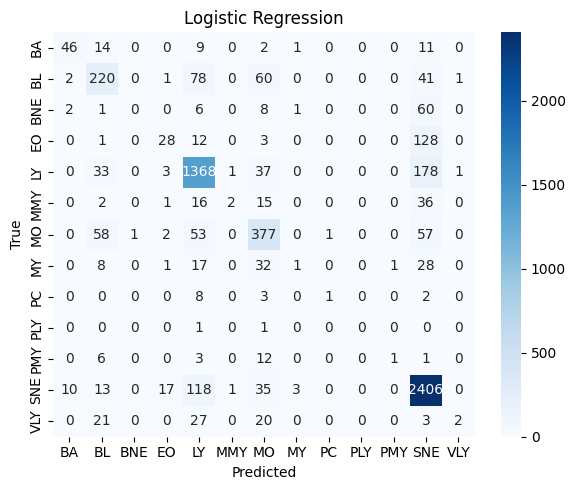

In [19]:
# Fitting Logistic Regression
lr_pipe = Pipeline([("scaler", StandardScaler()),
                    ("lr", LogisticRegression(max_iter=1000, random_state=SEED))])

# Fit + évaluation sur val
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_val)
f1_lr = macro_f1(y_val, y_pred_lr)

print(f"Val macro-F1: {f1_lr:.4f}")
print()
print(classification_report(y_val, y_pred_lr))
plot_confusion_matrix(y_val, y_pred_lr, classes, title="Logistic Regression")

results.append({"model": "Logistic Regression", "val_f1": f1_lr})

### 11.2 SVM (RBF kernel)

Val macro-F1: 0.3023

              precision    recall  f1-score   support

          BA       0.80      0.53      0.64        83
          BL       0.66      0.65      0.65       403
         BNE       0.00      0.00      0.00        78
          EO       0.92      0.13      0.23       172
          LY       0.86      0.83      0.84      1621
         MMY       0.00      0.00      0.00        72
          MO       0.67      0.69      0.68       549
          MY       0.00      0.00      0.00        88
          PC       0.00      0.00      0.00        14
         PLY       0.00      0.00      0.00         2
         PMY       0.00      0.00      0.00        23
         SNE       0.80      0.97      0.88      2603
         VLY       0.00      0.00      0.00        73

    accuracy                           0.79      5781
   macro avg       0.36      0.29      0.30      5781
weighted avg       0.75      0.79      0.76      5781



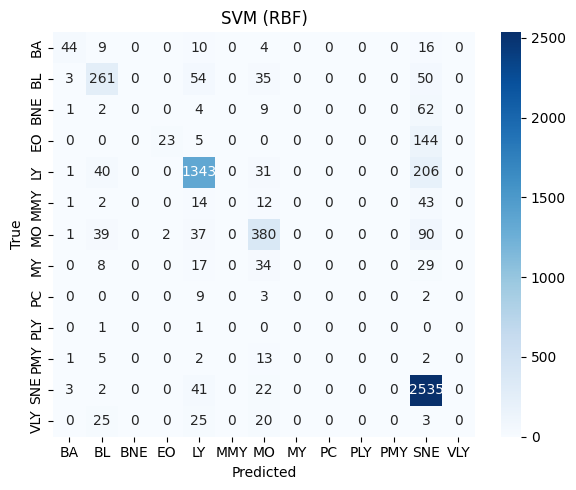

In [20]:
# Fitting SVM
svm_pipe = Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC(kernel="rbf", random_state=SEED))])

# Fit + évaluation sur val
svm_pipe.fit(X_train, y_train)
y_pred_svm = svm_pipe.predict(X_val)
f1_svm = macro_f1(y_val, y_pred_svm)

print(f"Val macro-F1: {f1_svm:.4f}")
print()
print(classification_report(y_val, y_pred_svm))
plot_confusion_matrix(y_val, y_pred_svm, classes, title="SVM (RBF)")

results.append({"model": "SVM (RBF)", "val_f1": f1_svm})

### 11.3 Random Forest

Val macro-F1: 0.3620

              precision    recall  f1-score   support

          BA       0.84      0.58      0.69        83
          BL       0.69      0.72      0.70       403
         BNE       1.00      0.01      0.03        78
          EO       0.89      0.24      0.38       172
          LY       0.83      0.85      0.84      1621
         MMY       0.67      0.03      0.05        72
          MO       0.65      0.71      0.68       549
          MY       0.25      0.01      0.02        88
          PC       1.00      0.14      0.25        14
         PLY       0.00      0.00      0.00         2
         PMY       0.00      0.00      0.00        23
         SNE       0.83      0.95      0.89      2603
         VLY       0.78      0.10      0.17        73

    accuracy                           0.80      5781
   macro avg       0.65      0.33      0.36      5781
weighted avg       0.79      0.80      0.78      5781



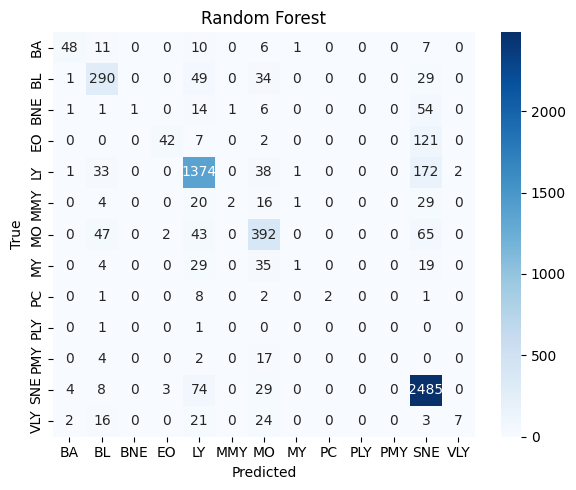

In [21]:
# Fitting Random Forest
rf_pipe = Pipeline([("rf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))])

# Fit + évaluation sur val
rf_pipe.fit(X_train, y_train)
y_pred_rf = rf_pipe.predict(X_val)
f1_rf = macro_f1(y_val, y_pred_rf)

print(f"Val macro-F1: {f1_rf:.4f}")
print()
print(classification_report(y_val, y_pred_rf))
plot_confusion_matrix(y_val, y_pred_rf, classes, title="Random Forest")

results.append({"model": "Random Forest", "val_f1": f1_rf})

### 11.4 MLP

Val macro-F1: 0.4291

              precision    recall  f1-score   support

          BA       0.77      0.65      0.71        83
          BL       0.62      0.73      0.67       403
         BNE       0.06      0.05      0.06        78
          EO       0.52      0.53      0.52       172
          LY       0.86      0.85      0.86      1621
         MMY       0.18      0.19      0.19        72
          MO       0.68      0.66      0.67       549
          MY       0.29      0.32      0.30        88
          PC       0.33      0.21      0.26        14
         PLY       0.00      0.00      0.00         2
         PMY       0.09      0.13      0.10        23
         SNE       0.90      0.90      0.90      2603
         VLY       0.49      0.26      0.34        73

    accuracy                           0.80      5781
   macro avg       0.45      0.42      0.43      5781
weighted avg       0.80      0.80      0.79      5781



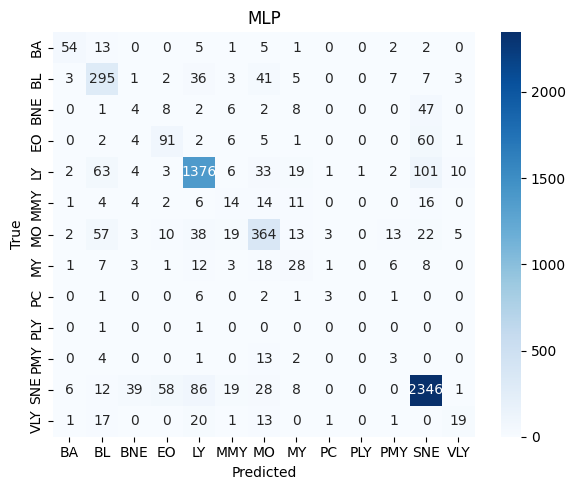

In [22]:
# Fitting MLP
mlp_pipe = Pipeline([("scaler", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=SEED))])

# Fit + évaluation sur val
mlp_pipe.fit(X_train, y_train)
y_pred_mlp = mlp_pipe.predict(X_val)
f1_mlp = macro_f1(y_val, y_pred_mlp)

print(f"Val macro-F1: {f1_mlp:.4f}")
print()
print(classification_report(y_val, y_pred_mlp))
plot_confusion_matrix(y_val, y_pred_mlp, classes, title="MLP")

results.append({"model": "MLP", "val_f1": f1_mlp})

## 12. Résultats

Macro-F1 et accuracy sur le split de validation (5 781 images, 20 % stratifié) :

| Modèle | Val macro-F1 | Accuracy |
|---|---:|---:|
| MLP (128, 64) | 0.4291 | 0.80 |
| Random Forest | 0.3620 | 0.80 |
| Logistic Regression | 0.3175 | 0.77 |
| SVM (RBF) | 0.3023 | 0.79 |

Le MLP est le meilleur classifieur classique, mais le macro-F1 reste faible.
L'accuracy élevée vient surtout des classes majoritaires (SNE, LY) : les classes rares et proches morphologiquement (BNE/SNE, MY/MMY/PMY) sont presque jamais reconnues, comme le montrent les rapports de classification ci-dessus.


## 13. Commentaires

**Intérêt de l'approche handcrafted features :**
- Rapide à mettre en œuvre, pas besoin de GPU
- Interprétable : on sait exactement quelles features sont utilisées
- Bonne baseline pour comprendre la difficulté du problème
- Cohérente avec les méthodes vues en cours (SVM, Random Forest, MLP, scaling)

**Limites :**
- Les features manuelles ne capturent pas toute la richesse visuelle des images
- La segmentation est approximative et peut introduire du bruit
- Difficile de rivaliser avec des approches deep learning sur des tâches de vision

**Prochaine étape :**  
Le second notebook explorera une approche **CNN / deep learning** (transfer learning avec un réseau pré-entraîné)  
qui devrait permettre d'améliorer significativement les performances.